# 06 · Fairness Audit, Bias Mitigation and Ethics (Milestone 4)

**Project:** An early-warning system for essential-price shocks across income quintiles in Pakistan (DS4SG, CS/SDP 312/314)

**The question.** An early warning is only useful for social protection if it works for the households that need
protection most. This notebook asks whether the final model of notebook 05 warns the poorest quintile (Q1) as well as
the richest (Q5), measures the gaps with the group fairness metrics of the brief, tests hypothesis H5 from Milestone 2,
finds where the gaps come from, and tries three ways of reducing them. It ends with an assessment against the FATEN
principles and with what would change in a real pilot.

| Rubric item (M4) | Section |
|---|---|
| Sensitive attribute | §1 |
| Demographic parity and disparate impact (80% rule), equalized odds, equal opportunity, predictive equality | §2, §3 |
| H5 (the model is less accurate for Q1), promised in Milestone 2 | §4 |
| Where the disparity comes from | §5 |
| Bias mitigation (pre-, in- and post-processing) | §6 |
| Fairness-accuracy trade-off (Pareto frontier) | §7 |
| Thresholds with asymmetric error costs across groups | §8 |
| Recommended policy, FATEN principles and living-lab deployment | §9, §10, §11 |

**Inputs:** the models, thresholds and predictions saved by notebook 05 in `models/m4_advanced/` (run notebook 05 first),
`data/processed/master_features.csv` and `data/processed/items_weekly_panel.csv`.
**Outputs:** figures `reports/figures/figF1`–`figF3` and tables `reports/tables/m4_*.csv`.

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from utils.plot_style import apply_style, GROUP_COLORS, SERIES, INK, INK_SECONDARY, GRID
from models import baseline as B
from models import advanced as A
from features.build_features import component

apply_style()
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
np.random.seed(A.SEED)

FIG_DIR, TABLE_DIR = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
MODEL_DIR = ROOT / "models" / "m4_advanced"
GROUPS = A.GROUPS
COLORS = {"Logistic regression": SERIES[0], "KNN": SERIES[1], "Decision tree": SERIES[2],
          "Random forest": SERIES[6], "Gradient boosting": SERIES[5]}


def caption(fig, text, y=-0.02):
    fig.text(0.01, y, text, ha="left", va="top", fontsize=9, color=INK_SECONDARY)

In [2]:
# Data, folds and the models of notebook 05 (run notebook 05 first)
df = A.load_model_data()
train, test = B.split_train_test(df)
X, y = train[A.FEATURES], train[A.TARGET]
Xt, yt = test[A.FEATURES], test[A.TARGET]
g_tr, g_te = train["group"].to_numpy(), test["group"].to_numpy()
folds = B.time_series_folds(train)
val = np.concatenate([va for _, va in folds])
yv, gv, wv = y.to_numpy()[val], g_tr[val], train["week_end"].to_numpy()[val]

card = json.loads((MODEL_DIR / "model_card.json").read_text(encoding="utf-8"))
FINAL = card["final_model"]
fitted = {n: joblib.load(MODEL_DIR / (n.lower().replace(" ", "_") + ".joblib")) for n in A.MODELS}
thr = {n: card["models"][n]["threshold"] for n in A.MODELS}
pred_oof = pd.read_csv(MODEL_DIR / "oof_predictions.csv", parse_dates=["week_end"])
pred_test = pd.read_csv(MODEL_DIR / "test_predictions.csv", parse_dates=["week_end"])
assert (pred_oof["week_end"].values == train["week_end"].values).all() and (pred_oof["group"].values == g_tr).all()
oof = {n: pred_oof[n].to_numpy() for n in A.MODELS}
p_test = {n: pred_test[n].to_numpy() for n in A.MODELS}
print(f"Final model: {FINAL}, threshold {thr[FINAL]} (chosen in notebook 05 on 2021-24 out-of-fold predictions)")
print(f"Audit data: {len(val)} validation rows (2021-24) and {len(test)} test rows (2025-26)")

Final model: Random forest, threshold 0.14 (chosen in notebook 05 on 2021-24 out-of-fold predictions)
Audit data: 1040 validation rows (2021-24) and 455 test rows (2025-26)


## 1. The sensitive attribute

* **Attribute: consumption quintile, a measure of socio-economic class.** PBS publishes the SPI separately for five
  groups of households ranked by monthly consumption expenditure. **Q1, the poorest fifth, is the unprivileged group and
  Q5, the richest fifth, the privileged group.** Q2 to Q4 are audited too.
* **What a positive prediction means here.** An alarm says "this group's prices will jump next week", and it is what
  would prepare a BISP top-up or other relief. The alarm is therefore the favourable outcome. A group that is warned
  less often, or whose real shocks are caught less often, is the one at a disadvantage. This is the reverse of a loan
  or policing model, where a positive prediction is the harm.
* **The unit is a quintile-week, not a person.** Each row is the price index of one fifth of urban households in one
  week. A missed Q1 shock means the poorest fifth of urban households met a price jump with no buffer.
* **Attributes we cannot audit.** The SPI covers 17 cities, so rural households are not in the data at all. Prices are
  national averages, so cities and provinces cannot be compared, and there is no information on gender or household
  type. §10 and §11 return to this.
* **Where the audit is run.** Mainly on the 2021–24 out-of-fold predictions, which give about 40 shock rows per quintile.
  The test period (6 to 9 shock rows per quintile) is a check. Every gap carries a bootstrap interval over whole weeks.

In [3]:
# Shock rates by quintile: the true positive rate of each group in the data
br = []
for lab, yy, gg in [("training 2019-24", y.to_numpy(), g_tr), ("validation years 2021-24", yv, gv),
                    ("test 2025-26", yt.to_numpy(), g_te)]:
    for g in GROUPS:
        m = gg == g
        br.append({"period": lab, "group": g, "rows": int(m.sum()), "shock rows": int(yy[m].sum()),
                   "shock rate": yy[m].mean()})
br = pd.DataFrame(br)
display(br.pivot(index="group", columns="period", values=["shock rows", "shock rate"]).round(3))
br.to_csv(TABLE_DIR / "m4_base_rates_by_group.csv", index=False)
w = train.pivot(index="week_end", columns="group", values=A.TARGET)
print(f"Training weeks followed by a shock in at least one quintile: {(w.sum(axis=1) > 0).sum()}; "
      f"in all five: {(w.sum(axis=1) == 5).sum()}; in Q1 but not Q5: {((w['Q1'] == 1) & (w['Q5'] == 0)).sum()}; "
      f"in Q5 but not Q1: {((w['Q5'] == 1) & (w['Q1'] == 0)).sum()}")

shock rows                                             shock rate                                          
period test 2025-26 training 2019-24 validation years 2021-24 test 2025-26 training 2019-24 validation years 2021-24
group                                                                                                               
Q1              7.0             44.0                     38.0        0.077            0.163                    0.183
Q2              9.0             51.0                     43.0        0.099            0.189                    0.207
Q3              6.0             46.0                     40.0        0.066            0.170                    0.192
Q4              7.0             50.0                     44.0        0.077            0.185                    0.212
Q5              6.0             41.0                     38.0        0.066            0.152                    0.183

Training weeks followed by a shock in at least one quintile: 62; in all five: 27; in Q1 but not Q5: 17; in Q5 but not Q1: 14


**Reading the base rates.** Every quintile has almost the same shock rate. In the validation years each had between 38
and 44 shock rows out of 208 (18% to 21%), and in the test period between 6 and 9 out of 91. Most shocks hit several
quintiles in the same week, but not all. Of the 62 training weeks followed by a shock somewhere, 27 hit all five
quintiles, 17 hit Q1 but not Q5, and 14 hit Q5 but not Q1. Equal base rates matter for the audit in two ways.
* A model can only be calibrated within groups and have equal error rates at the same time when the groups' base rates
  are equal. Here they nearly are, so we can ask for all the criteria together.
* Demographic parity, which ignores whether a shock came, is a reasonable check here, because a fair model should warn
  groups with the same shock rate equally often.

## 2. Group fairness metrics

All metrics compare the five quintiles at the alarm threshold of each model (one shared threshold, chosen on 2021–24 in
notebook 05). Q1 against Q5 is the main comparison, and the range over all five quintiles is shown too.

| Metric | Definition | Fair when | What a gap would mean here |
|---|---|---|---|
| Disparate impact ratio | alert rate of Q1 / alert rate of Q5 | between 0.8 and 1.25 (the 80% rule) | below 0.8, the poorest are warned disproportionately less often |
| Demographic parity difference | alert rate of Q1 − alert rate of Q5 | 0 | as above, as a difference |
| Equal opportunity difference | recall (TPR) of Q1 − recall of Q5 | 0 | negative, more of Q1's real shocks arrive without warning |
| Predictive equality difference | false-positive rate of Q1 − FPR of Q5 | 0 | positive, Q1's calm weeks are more often false alarms |
| Equalized odds gap | the larger of the absolute TPR and FPR differences | 0 | both kinds of error are shared unequally |

**Which one matters most.** A missed shock is the costly error (a missed shock costs five false alarms), and it falls on
the household, so **equal opportunity** is our main criterion. Predictive equality matters for trust and for the fiscal
cost of false alarms. Demographic parity ignores whether a shock actually came, but because the shock rate is almost
the same in every quintile (§1), a model that serves all groups alike should also roughly meet it.

In [4]:
# Group fairness metrics of every M4 learner at its own threshold, validation years and test period
rows, rates_store = [], {}
for period, yy, gg, preds in [("2021-24 (out-of-fold)", yv, gv, {n: oof[n][val] for n in A.MODELS}),
                              ("test 2025-26", yt.to_numpy(), g_te, p_test)]:
    for n in A.MODELS:
        r = A.group_rates(yy, preds[n], gg, thr[n])
        rates_store[(period, n)] = r
        rows.append({"period": period, "model": n, **A.fairness_summary(r)})
audit = pd.DataFrame(rows).set_index(["period", "model"])
cols = ["disparate impact ratio (Q1/Q5)", "equal opportunity diff. (TPR Q1-Q5)",
        "predictive equality diff. (FPR Q1-Q5)", "equalized odds gap (Q1 vs Q5)",
        "min/max alert-rate ratio (all groups)", "TPR range (all groups)", "FPR range (all groups)"]
display(audit[cols].round(3))
audit.to_csv(TABLE_DIR / "m4_fairness_all_models.csv")
print("80% rule (disparate impact ratio below 0.8 or above 1.25):")
print(audit["disparate impact ratio (Q1/Q5)"].apply(lambda v: "violated" if (v < 0.8 or v > 1.25) else "met").unstack(0))

disparate impact ratio (Q1/Q5)  equal opportunity diff. (TPR Q1-Q5)  predictive equality diff. (FPR Q1-Q5)  \
period                model                                                                                                                             
2021-24 (out-of-fold) Logistic regression                           1.012                               -0.132                                  0.035   
                      KNN                                           1.035                               -0.053                                  0.035   
                      Decision tree                                 0.963                               -0.105                                 -0.012   
                      Random forest                                 1.050                               -0.026                                  0.035   
                      Gradient boosting                             1.021                               -0.079                                  0.029   
test 2025-26          Logistic regression                           1.000                               -0.190                                  0.013   
                      KNN                                           1.037                               -0.238                                  0.027   
                      Decision tree                                 1.000                                0.000                                 -0.003   
                      Random forest                                 1.115                                0.071                                  0.027   
                      Gradient boosting                             1.150                                0.238                                  0.014   

                                           equalized odds gap (Q1 vs Q5)  min/max alert-rate ratio (all groups)  TPR range (all groups)  FPR range (all groups)  
period                model                                                                                                                                      
2021-24 (out-of-fold) Logistic regression                          0.132                                  0.851                   0.132                   0.094  
                      KNN                                          0.053                                  0.891                   0.066                   0.081  
                      Decision tree                                0.105                                  0.963                   0.105                   0.021  
                      Random forest                                0.035                                  0.953                   0.127                   0.040  
                      Gradient boosting                            0.079                                  0.970                   0.087                   0.029  
test 2025-26          Logistic regression                          0.190                                  0.583                   0.190                   0.063  
                      KNN                                          0.238                                  0.806                   0.238                   0.082  
                      Decision tree                                0.003                                  1.000                   0.000                   0.008  
                      Random forest                                0.071                                  0.828                   0.127                   0.060  
                      Gradient boosting                            0.238                                  0.800                   0.238                   0.044

80% rule (disparate impact ratio below 0.8 or above 1.25):
period              2021-24 (out-of-fold) test 2025-26
model                                                 
Decision tree                         met          met
Gradient boosting                     met          met
KNN                                   met          met
Logistic regression                   met          met
Random forest                         met          met


## 3. The final model in detail, with uncertainty

Rates for each quintile at the shared threshold, then 95% intervals for the fairness metrics from 2,000 bootstrap
resamples of whole weeks (the five quintile rows of a week are drawn together, because they share their signals).

In [5]:
# The final model in detail: rates for each quintile
for period in ["2021-24 (out-of-fold)", "test 2025-26"]:
    print(f"{FINAL}, {period}, threshold {thr[FINAL]}")
    display(rates_store[(period, FINAL)][["rows", "shock rows", "shock rate", "alert rate", "TPR (recall)", "FPR",
                                          "precision", "Brier", "ROC-AUC"]].round(3))
pd.concat({p: rates_store[(p, FINAL)] for p in ["2021-24 (out-of-fold)", "test 2025-26"]}).to_csv(
    TABLE_DIR / "m4_final_rates_by_group.csv")

Random forest, 2021-24 (out-of-fold), threshold 0.14


,rows,shock rows,shock rate,alert rate,TPR (recall),FPR,precision,Brier,ROC-AUC
group,,,,,,,,,
Q1,208,38,0.183,0.510,0.737,0.459,0.264,0.148,0.639
Q2,208,43,0.207,0.510,0.744,0.448,0.302,0.160,0.647
Q3,208,40,0.192,0.505,0.725,0.452,0.276,0.154,0.628
Q4,208,44,0.212,0.500,0.636,0.463,0.269,0.163,0.628
Q5,208,38,0.183,0.486,0.763,0.424,0.287,0.136,0.720


Random forest, test 2025-26, threshold 0.14


,rows,shock rows,shock rate,alert rate,TPR (recall),FPR,precision,Brier,ROC-AUC
group,,,,,,,,,
Q1,91,7,0.077,0.319,0.571,0.298,0.138,0.074,0.629
Q2,91,9,0.099,0.286,0.444,0.268,0.154,0.090,0.653
Q3,91,6,0.066,0.264,0.500,0.247,0.125,0.064,0.680
Q4,91,7,0.077,0.264,0.571,0.238,0.167,0.072,0.699
Q5,91,6,0.066,0.286,0.500,0.271,0.115,0.062,0.724


In [6]:
# Uncertainty: week-block bootstrap of the fairness metrics of the final model (2,000 resamples of whole weeks)
bf = {}
for period, yy, gg, pp, ww in [("2021-24 (out-of-fold)", yv, gv, oof[FINAL][val], wv),
                               ("test 2025-26", yt.to_numpy(), g_te, p_test[FINAL], test["week_end"].to_numpy())]:
    b = A.bootstrap_fairness(yy, pp, gg, ww, thr[FINAL])
    point = A.fairness_summary(A.group_rates(yy, pp, gg, thr[FINAL]))
    bf[period] = pd.DataFrame({"estimate": pd.Series(point)[cols], "95% CI low": b[cols].quantile(0.025),
                               "95% CI high": b[cols].quantile(0.975), "resamples": len(b)})
bf = pd.concat(bf)
display(bf.round(3))
bf.to_csv(TABLE_DIR / "m4_fairness_bootstrap_final.csv")

estimate  95% CI low  95% CI high  resamples
2021-24 (out-of-fold) disparate impact ratio (Q1/Q5)            1.050       0.979        1.131       2000
                      equal opportunity diff. (TPR Q1-Q5)      -0.026      -0.178        0.122       2000
                      predictive equality diff. (FPR Q1-Q5)     0.035      -0.012        0.081       2000
                      equalized odds gap (Q1 vs Q5)             0.035       0.014        0.185       2000
                      min/max alert-rate ratio (all groups)     0.953       0.879        0.981       2000
                      TPR range (all groups)                    0.127       0.062        0.262       2000
                      FPR range (all groups)                    0.040       0.018        0.086       2000
test 2025-26          disparate impact ratio (Q1/Q5)            1.115       0.864        1.500       1992
                      equal opportunity diff. (TPR Q1-Q5)       0.071      -0.551        0.657       1992
                      predictive equality diff. (FPR Q1-Q5)     0.027      -0.061        0.114       1992
                      equalized odds gap (Q1 vs Q5)             0.071       0.023        0.667       1992
                      min/max alert-rate ratio (all groups)     0.828       0.613        0.926       1992
                      TPR range (all groups)                    0.127       0.111        0.800       1992
                      FPR range (all groups)                    0.060       0.025        0.139       1992

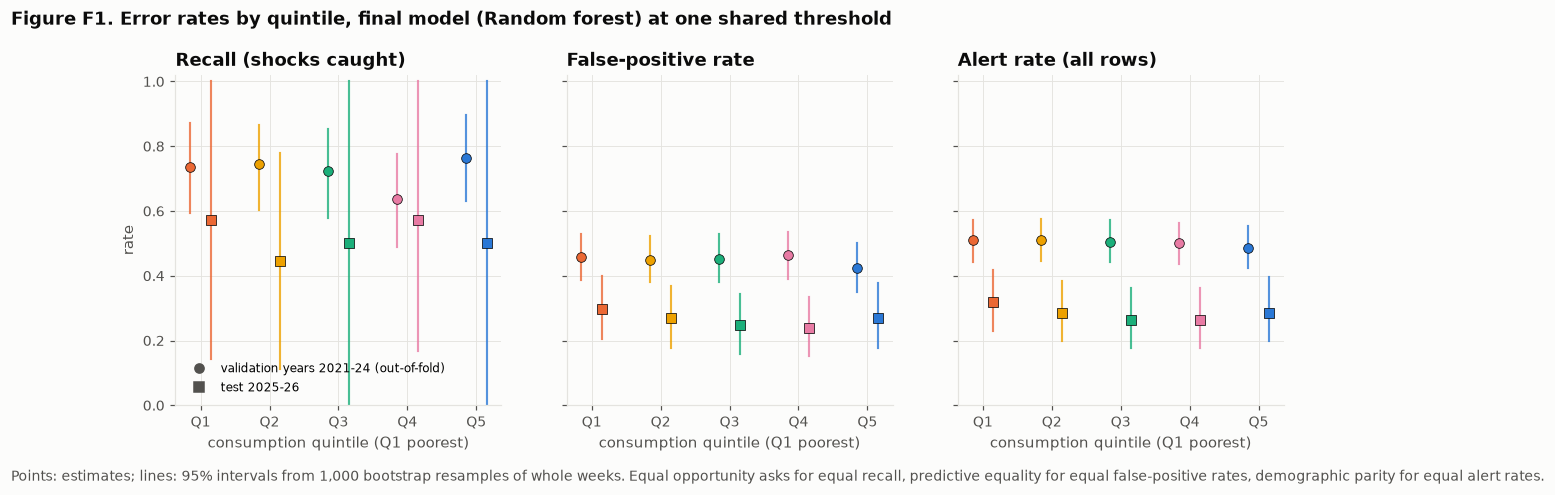

In [7]:
# Figure F1: recall, false-positive rate and alert rate by quintile for the final model, with bootstrap intervals
def boot_rates(yy, pp, gg, ww, t, n_boot=1000):
    rng = np.random.default_rng(A.SEED)
    uniq = np.unique(ww)
    rows_of = {w: np.flatnonzero(ww == w) for w in uniq}
    out = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_of[w] for w in rng.choice(uniq, size=len(uniq), replace=True)])
        out.append(A.group_rates(yy[idx], pp[idx], gg[idx], t)[["TPR (recall)", "FPR", "alert rate"]])
    return pd.concat(out, keys=range(len(out)))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for j, (period, yy, gg, pp, ww, mk) in enumerate([("2021-24 (out-of-fold)", yv, gv, oof[FINAL][val], wv, "o"),
                                                 ("test 2025-26", yt.to_numpy(), g_te, p_test[FINAL], test["week_end"].to_numpy(), "s")]):
    pt = A.group_rates(yy, pp, gg, thr[FINAL])
    bb = boot_rates(yy, pp, gg, ww, thr[FINAL])
    for ax, metric in zip(axes, ["TPR (recall)", "FPR", "alert rate"]):
        for i, g in enumerate(GROUPS):
            q = bb.xs(g, level=1)[metric].dropna().quantile([0.025, 0.975])
            xx = i + (j - 0.5) * 0.3
            ax.plot([xx, xx], q.values, color=GROUP_COLORS[g], lw=1.4, alpha=0.8)
            ax.scatter(xx, pt.loc[g, metric], color=GROUP_COLORS[g], marker=mk, s=40, zorder=3,
                       edgecolor=INK, linewidth=0.5, label=period if (i == 0) else None)
for ax, metric, ttl in zip(axes, ["TPR (recall)", "FPR", "alert rate"],
                           ["Recall (shocks caught)", "False-positive rate", "Alert rate (all rows)"]):
    ax.set_xticks(range(5), GROUPS)
    ax.set(title=ttl, xlabel="consumption quintile (Q1 poorest)", ylim=(0, 1.02))
axes[0].set_ylabel("rate")
handles = [plt.Line2D([], [], marker="o", ls="", color=INK_SECONDARY, label="validation years 2021-24 (out-of-fold)"),
           plt.Line2D([], [], marker="s", ls="", color=INK_SECONDARY, label="test 2025-26")]
axes[0].legend(handles=handles, loc="lower left", fontsize=8)
fig.suptitle(f"Figure F1. Error rates by quintile, final model ({FINAL}) at one shared threshold", x=0.01, ha="left",
             fontweight="bold", color=INK, y=1.03)
caption(fig, "Points: estimates; lines: 95% intervals from 1,000 bootstrap resamples of whole weeks. Equal opportunity asks "
             "for equal recall, predictive equality for equal false-positive rates, demographic parity for equal alert rates.", y=-0.04)
fig.savefig(FIG_DIR / "figF1_rates_by_quintile.png")
plt.show()

**Reading the audit**
* **Demographic parity holds for every learner.** In 2021–24 the disparate impact ratio lies between 0.96 and 1.05, well
  inside the 80% rule. For the forest it is 1.05 (95% interval 0.98 to 1.13), so Q1 is warned as often as Q5, or
  slightly more. The reason is built into the data, as most signals are week-level and the same for every quintile.
* **Equal opportunity leans against Q1 in every learner.** Q1's recall is below Q5's in all five learners in 2021–24,
  by 2.6 points for the forest and up to 13.2 points for logistic regression. For the forest the gap is small and its
  interval is wide (−0.18 to +0.12). The largest recall gap of the forest is between Q4 (0.64) and Q5 (0.76), not between
  Q1 and Q5.
* **Predictive equality nearly holds.** Q1's calm weeks are falsely alarmed slightly more often (FPR 0.46 against 0.42,
  interval −0.01 to +0.08).
* **The bigger difference is in ranking, not at the threshold.** Over the four validation years the forest's AUC within
  each group is 0.64 for Q1 and 0.72 for Q5, and its Brier loss is 0.148 against 0.136. The shared threshold hides this, because it happens to sit
  where the two groups' recalls are similar.
* **The test period cannot settle fairness.** With 6 to 9 shock rows per quintile, one shock moves a quintile's recall by
  11 to 17 points. The forest caught 4 of 7 Q1 shocks and 3 of 6 Q5 shocks, and the bootstrap interval of the
  equal-opportunity gap runs from −0.55 to +0.66.

## 4. Hypothesis H5: is the model less accurate for the poorest quintile?

From the Milestone 2 manuscript, with Brier loss *L* (the squared difference between the predicted probability and the
0/1 outcome, which rewards probabilities that are both sharp and calibrated):

* **H0:** E[*L*<sub>Q1</sub>] = E[*L*<sub>Q5</sub>]
* **H1:** E[*L*<sub>Q1</sub>] > E[*L*<sub>Q5</sub>] (one-sided)

**Test (Diebold–Mariano, planned in Milestone 2).** For every week, take the loss difference
*d*<sub>t</sub> = *L*<sub>Q1,t</sub> − *L*<sub>Q5,t</sub>. Under H0 its mean is zero. The test is a paired t-test over weeks,
except that the standard error of the mean uses the Newey–West formula, because weekly losses are autocorrelated (a bad
week tends to follow a bad week) and an ordinary standard error would be too small. We use 4 lags (one month) and
show 1 to 13 as a robustness check. 5% level, p-value approach.

In [8]:
# H5: is the final model less accurate for Q1 than for Q5? Brier loss per week, Diebold-Mariano test
def weekly_loss(frame, p, g):
    m = (frame["group"] == g).to_numpy()
    return pd.Series((p[m] - frame[A.TARGET].to_numpy()[m]) ** 2, index=frame["week_end"].to_numpy()[m])

rows = []
tr_val = train.iloc[val]
for period, frame, pp in [("2021-24 (out-of-fold)", tr_val, oof[FINAL][val]), ("test 2025-26", test, p_test[FINAL])]:
    l1, l5 = weekly_loss(frame, pp, "Q1"), weekly_loss(frame, pp, "Q5")
    assert (l1.index == l5.index).all()
    for lags in [4]:
        dm = A.diebold_mariano(l1.values, l5.values, lags=lags)
        rows.append({"period": period, "Brier Q1": l1.mean(), "Brier Q5": l5.mean(), **dm})
h5 = pd.DataFrame(rows).set_index("period")
display(h5.round(4))
h5.to_csv(TABLE_DIR / "m4_h5_diebold_mariano.csv")

# Robustness: other lag lengths for the HAC variance, and the same test for every M4 learner (2021-24)
rob = []
l1, l5 = weekly_loss(tr_val, oof[FINAL][val], "Q1"), weekly_loss(tr_val, oof[FINAL][val], "Q5")
for lags in [1, 2, 4, 8, 13]:
    rob.append({"lags": lags, **A.diebold_mariano(l1.values, l5.values, lags=lags)})
display(pd.DataFrame(rob).set_index("lags")[["mean diff", "HAC SE", "t", "p (one-sided)"]].round(4))
rows = []
for n in A.MODELS:
    a, b = weekly_loss(tr_val, oof[n][val], "Q1"), weekly_loss(tr_val, oof[n][val], "Q5")
    rows.append({"model": n, "Brier Q1": a.mean(), "Brier Q5": b.mean(), **A.diebold_mariano(a.values, b.values)})
display(pd.DataFrame(rows).set_index("model")[["Brier Q1", "Brier Q5", "mean diff", "t", "p (one-sided)"]].round(4))

,Brier Q1,Brier Q5,mean diff,HAC SE,t,p (one-sided),p (two-sided),weeks
period,,,,,,,,
2021-24 (out-of-fold),0.1480,0.1360,0.0120,0.0183,0.6555,0.2561,0.5122,208
test 2025-26,0.0738,0.0624,0.0114,0.0258,0.4417,0.3293,0.6587,91


,mean diff,HAC SE,t,p (one-sided)
lags,,,,
1,0.012,0.0168,0.7139,0.2376
2,0.012,0.0172,0.6988,0.2423
4,0.012,0.0183,0.6555,0.2561
8,0.012,0.0199,0.6052,0.2725
13,0.012,0.0210,0.5720,0.2837


,Brier Q1,Brier Q5,mean diff,t,p (one-sided)
model,,,,,
Logistic regression,0.2474,0.2456,0.0019,2.1910,0.0142
KNN,0.1476,0.1415,0.0061,0.3058,0.3799
Decision tree,0.1579,0.1436,0.0143,0.7065,0.2399
Random forest,0.1480,0.1360,0.0120,0.6555,0.2561
Gradient boosting,0.1502,0.1372,0.0130,0.6872,0.2460


**Decision on H5.** The direction is as Milestone 2 expected. The forest's Brier loss is higher for Q1 than for Q5,
in the validation years (0.148 against 0.136) and in the test period (0.074 against 0.062). But the weekly
differences are noisy. The mean difference is 0.012 with a Newey–West standard error of 0.018 (t = 0.66, one-sided
p = 0.26) in 2021–24, and p = 0.33 in the test period. **We fail to reject H0.** The result does not depend on the
number of lags (1 to 13, p = 0.24 to 0.28). All five learners show the same direction. Only logistic regression's gap
is significant (p = 0.014), and it is tiny (0.002), because its probabilities sit near 0.5 for every row. The final
model is somewhat less accurate for the poorest quintile, but with four years of weekly data the gap cannot be told
apart from chance.

## 5. Where does a disparity come from?

Most features are week-level signals that are the same for all five quintiles (the rupee, the calendar, component
inflation). Only the group's own SPI history, its recent shocks, its 26-week shock rate and the quintile indicators
differ between rows of the same week. A model built on these signals tends to raise one alarm for the whole week.
But shocks of different origin hit different quintiles. Milestone 3 (H3) found that food, and perishables above all,
widen the inflation gap against Q1, while motor fuel hits Q5 harder. Each shock below is labelled by the price
component with the largest upward impact on the SPI in the shock week, as in Milestone 3.

In [9]:
# Where does a disparity come from? Label every shock by the price component that drove it that week
items = pd.read_csv(ROOT / "data" / "processed" / "items_weekly_panel.csv", parse_dates=["week_end"])
items["component"] = [component(i, c) for i, c in zip(items["item_id"], items["category"])]
items["impact"] = items["impact_combined"].fillna(items["weight_combined"] * items["price_wow_pct"] / 100)
items = items.dropna(subset=["impact"])          # the first week has no previous price, so no impact
driver = items.loc[items.groupby("week_end")["impact"].idxmax(), ["week_end", "component"]].set_index("week_end")["component"]
nice = {"perishables": "food: perishables", "staples": "food: staples", "utilities": "energy: utility tariffs",
        "motor_fuel": "energy: motor fuel", "market_energy": "energy: LPG, firewood", "nonfood": "other non-food"}

frames = []
for period, frame, pp in [("2021-24 (out-of-fold)", train.iloc[val], oof[FINAL][val]), ("test 2025-26", test, p_test[FINAL])]:
    f = frame[["week_end", "group", A.TARGET]].copy()
    f["driver"] = (f["week_end"] + pd.Timedelta(days=7)).map(driver).map(nice)
    f["alert"] = (pp >= thr[FINAL]).astype(int)
    f["period"] = period
    frames.append(f[f[A.TARGET] == 1])
shocks = pd.concat(frames)
mix = (shocks.groupby(["period", "group"])["driver"].value_counts(normalize=True).unstack(fill_value=0))
print("Share of each quintile's shock rows, by the component that drove the shock:")
display(mix.round(2))
caught = shocks.groupby(["period", "driver"])["alert"].agg(["mean", "sum", "size"]).rename(
    columns={"mean": "recall", "sum": "caught", "size": "shock rows"})
print("Recall of the final model by shock driver:")
display(caught.round(2))
mix.to_csv(TABLE_DIR / "m4_shock_driver_mix_by_group.csv")
caught.to_csv(TABLE_DIR / "m4_recall_by_driver.csv")

Share of each quintile's shock rows, by the component that drove the shock:


driver                       energy: motor fuel  energy: utility tariffs  food: perishables  food: staples  other non-food
period                group                                                                                               
2021-24 (out-of-fold) Q1                   0.16                     0.32               0.42           0.11            0.00
                      Q2                   0.16                     0.30               0.44           0.09            0.00
                      Q3                   0.20                     0.35               0.35           0.10            0.00
                      Q4                   0.20                     0.34               0.36           0.09            0.00
                      Q5                   0.29                     0.37               0.24           0.05            0.05
test 2025-26          Q1                   0.00                     0.29               0.57           0.14            0.00
                      Q2                   0.11                     0.44               0.33           0.11            0.00
                      Q3                   0.33                     0.33               0.17           0.17            0.00
                      Q4                   0.29                     0.14               0.43           0.14            0.00
                      Q5                   0.33                     0.17               0.33           0.17            0.00

Recall of the final model by shock driver:


recall  caught  shock rows
period                driver                                             
2021-24 (out-of-fold) energy: motor fuel         0.88      36          41
                      energy: utility tariffs    0.69      47          68
                      food: perishables          0.62      46          74
                      food: staples              0.89      16          18
                      other non-food             0.50       1           2
test 2025-26          energy: motor fuel         0.57       4           7
                      energy: utility tariffs    0.30       3          10
                      food: perishables          0.46       6          13
                      food: staples              1.00       5           5

**Reading the sources**
* **Q1's shocks come from different places than Q5's.** In 2021–24, 42% of Q1's shock rows were driven by perishables
  (tomatoes, onions, chicken and similar), against 24% of Q5's. Motor fuel drove 29% of Q5's shocks but only 16% of
  Q1's. This is the rotating burden of Milestones 2 and 3, now seen from the shocks' side.
* **The forest catches fuel shocks best and perishable shocks worst.** Its recall is 0.88 for motor-fuel shocks and 0.89
  for staple-food shocks, but 0.69 for utility-tariff shocks and 0.62 for perishable shocks. In the test period the order
  is the same (perishables 0.46, utility tariffs 0.30).
* **This is the mechanism behind the gaps.** The poorest quintile is exposed most to exactly the shocks that have no
  lead signal in our data (supply shocks to perishables and administered tariff decisions). That explains why the forest
  ranks Q1's weeks worse (§3) and why its signals carry less information for Q1 (notebook 05, §11). A different
  threshold can rebalance who receives alarms, but it cannot create the missing signal. That needs new data, such as
  wholesale perishable prices or the tariff calendar (Milestone 5).

## 6. Bias mitigation: pre-, in- and post-processing

Three families of methods, each set up on the 2021–24 out-of-fold predictions only and then scored once on the test
period.

* **Pre-processing: reweighing.** Each combination of quintile and outcome gets the weight
  P(quintile) × P(outcome) / P(quintile, outcome), computed on each fold's training rows. In the weighted data the
  shock rate is the same in every quintile, so the model cannot learn that one quintile is "usually calm". The model is
  retrained with these weights.
* **In-processing: group-weighted training cost.** Q1's shock rows count twice in the model's training loss. While it
  learns, the model pays more for a missed Q1 shock than for any other error.
* **Post-processing: one threshold per quintile.** The model is unchanged and only the alarm threshold differs by group.
  Three versions are compared.
  * *Cost-based:* each quintile's threshold minimises its own cost of errors, with a missed Q1 shock costing ten false
    alarms (twice the usual five) and every other quintile's miss costing five.
  * *Equal opportunity:* the five thresholds with the lowest total cost whose recalls differ by at most 0.05.
  * *Demographic parity:* the five thresholds with the lowest total cost whose alert rates meet the 80% rule.

**Why a missed Q1 shock counts twice.** This is a value judgement, not an estimate. A Q1 household spends a larger share of
its budget on food and energy than richer households and has the least savings to absorb a jump, so it is the most likely to cope by
eating less or borrowing, which is hard to undo. The factor of 2 sits between treating all households alike (1) and an
extreme weight. §8 shows 1, 1.5, 2 and 3.

**Is it fair to use the quintile in the decision?** For decisions about individuals, using a protected attribute can
itself be discrimination. Here the quintile is the unit the policy acts on (BISP targets the poorest households), so
group-specific thresholds are explicit and transparent instead of hidden. The data never identify a person.

In [10]:
# Bias mitigation: three families, each chosen on the 2021-24 out-of-fold predictions only
est = fitted[FINAL]
policies = {}
# (0) no mitigation: one shared threshold at 5:1
policies["No mitigation (shared threshold)"] = dict(oof=oof[FINAL], test=p_test[FINAL], thr=thr[FINAL])

# (1) pre-processing: reweighing, weights computed on each fold's training rows
oof_rw = A.oof_predict(est, X, y, folds, weight_fn=A.reweighing_weights, groups=g_tr)
fit_rw = A.fit(est, X, y, A.reweighing_weights(g_tr, y))
policies["Pre: reweighing"] = dict(oof=oof_rw, test=fit_rw.predict_proba(Xt)[:, 1], thr=B.best_threshold(y, oof_rw))

# (2) in-processing: a missed Q1 shock costs twice as much in the training loss
oof_in = A.oof_predict(est, X, y, folds, weight_fn=A.group_cost_weights, groups=g_tr)
fit_in = A.fit(est, X, y, A.group_cost_weights(g_tr, y))
policies["In: Q1 shocks weighted x2 in training"] = dict(oof=oof_in, test=fit_in.predict_proba(Xt)[:, 1],
                                                          thr=B.best_threshold(y, oof_in))

# (3) post-processing: one threshold per quintile
costs_q1 = A.miss_costs(A.Q1_MISS_MULT)
policies["Post: quintile thresholds, Q1 miss x2"] = dict(oof=oof[FINAL], test=p_test[FINAL],
                                                         thr=A.group_thresholds(y, oof[FINAL], g_tr, costs_q1))
EO_EPS = 0.05     # recalls of the five quintiles may differ by at most 5 percentage points
eo = A.pareto_frontier(yv, oof[FINAL][val], gv, kind="TPR", eps_grid=[EO_EPS]).iloc[0]
policies[f"Post: equal opportunity (recall gap <= {EO_EPS:.2f})"] = dict(oof=oof[FINAL], test=p_test[FINAL], thr=eo["thresholds"])
di = A.pareto_frontier(yv, oof[FINAL][val], gv, kind="DI", eps_grid=[0.2]).iloc[0]
policies["Post: demographic parity (80% rule)"] = dict(oof=oof[FINAL], test=p_test[FINAL], thr=di["thresholds"])
# the full frontiers, for the trade-off figure in section 7
fr_tpr = A.pareto_frontier(yv, oof[FINAL][val], gv, kind="TPR")
fr_di = A.pareto_frontier(yv, oof[FINAL][val], gv, kind="DI")

for k, v in policies.items():
    t = v["thr"]
    print(f"{k}: thresholds " + (str({g: round(x, 2) for g, x in t.items()}) if isinstance(t, dict) else f"{t:.2f} for every quintile"))

No mitigation (shared threshold): thresholds 0.14 for every quintile
Pre: reweighing: thresholds 0.12 for every quintile
In: Q1 shocks weighted x2 in training: thresholds 0.17 for every quintile
Post: quintile thresholds, Q1 miss x2: thresholds {'Q1': 0.09, 'Q2': 0.14, 'Q3': 0.14, 'Q4': 0.11, 'Q5': 0.12}
Post: equal opportunity (recall gap <= 0.05): thresholds {'Q1': 0.14, 'Q2': 0.14, 'Q3': 0.14, 'Q4': 0.11, 'Q5': 0.14}
Post: demographic parity (80% rule): thresholds {'Q1': 0.14, 'Q2': 0.14, 'Q3': 0.14, 'Q4': 0.11, 'Q5': 0.12}


In [11]:
# Accuracy and fairness of each policy, on the validation years and on the test period
def evaluate(yy, pp, gg, t):
    r = A.group_rates(yy, pp, gg, t)
    tp, fp, fn, tn = r["TP"].sum(), r["FP"].sum(), r["FN"].sum(), r["TN"].sum()
    never = B.COST_FN * yy.sum()
    s = A.fairness_summary(r)
    return {"cost / never (5:1)": A.total_cost(yy, pp, gg, t) / never,
            "cost / never (Q1 miss x2)": A.total_cost(yy, pp, gg, t, costs_q1) / (never + B.COST_FN * yy[gg == "Q1"].sum()),
            "accuracy": (tp + tn) / len(yy), "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn), "recall Q1": r.loc["Q1", "TPR (recall)"], "recall Q5": r.loc["Q5", "TPR (recall)"],
            "disparate impact ratio (Q1/Q5)": s["disparate impact ratio (Q1/Q5)"],
            "equal opportunity diff. (TPR Q1-Q5)": s["equal opportunity diff. (TPR Q1-Q5)"],
            "predictive equality diff. (FPR Q1-Q5)": s["predictive equality diff. (FPR Q1-Q5)"],
            "TPR range (all groups)": s["TPR range (all groups)"]}

rows = []
for k, v in policies.items():
    rows.append({"policy": k, "period": "2021-24 (out-of-fold)", **evaluate(yv, v["oof"][val], gv, v["thr"])})
    rows.append({"policy": k, "period": "test 2025-26", **evaluate(yt.to_numpy(), v["test"], g_te, v["thr"])})
pol = pd.DataFrame(rows).set_index(["period", "policy"])
display(pol.round(3))
pol.to_csv(TABLE_DIR / "m4_mitigation_policies.csv")

,,cost / never (5:1),cost / never (Q1 miss x2),accuracy,recall,precision,F1,recall Q1,recall Q5,disparate impact ratio (Q1/Q5),equal opportunity diff. (TPR Q1-Q5),predictive equality diff. (FPR Q1-Q5),TPR range (all groups)
period,policy,,,,,,,,,,,,
2021-24 (out-of-fold),No mitigation (shared threshold),0.651,0.590,0.584,0.719,0.280,0.403,0.737,0.763,1.050,-0.026,0.035,0.127
test 2025-26,No mitigation (shared threshold),1.120,1.005,0.719,0.514,0.140,0.220,0.571,0.500,1.115,0.071,0.027,0.127
2021-24 (out-of-fold),Pre: reweighing,0.663,0.596,0.545,0.754,0.266,0.393,0.763,0.842,1.026,-0.079,0.035,0.160
test 2025-26,Pre: reweighing,1.166,1.043,0.675,0.600,0.135,0.221,0.571,0.667,1.031,-0.095,0.016,0.111
2021-24 (out-of-fold),In: Q1 shocks weighted x2 in training,0.671,0.607,0.603,0.670,0.282,0.397,0.737,0.711,1.096,0.026,0.047,0.123
test 2025-26,In: Q1 shocks weighted x2 in training,1.074,0.967,0.754,0.457,0.147,0.222,0.571,0.333,1.300,0.238,0.050,0.238
2021-24 (out-of-fold),"Post: quintile thresholds, Q1 miss x2",0.643,0.559,0.530,0.798,0.266,0.399,0.895,0.868,1.294,0.026,0.200,0.170
test 2025-26,"Post: quintile thresholds, Q1 miss x2",1.229,1.071,0.651,0.600,0.127,0.209,0.714,0.667,1.531,0.048,0.194,0.270
2021-24 (out-of-fold),Post: equal opportunity (recall gap <= 0.05),0.637,0.578,0.574,0.749,0.279,0.407,0.737,0.763,1.050,-0.026,0.035,0.048


**Reading the mitigation results**
* **Pre-processing (reweighing) changes almost nothing, and what it changes goes the wrong way.** Because the shock rate
  is nearly the same in every quintile, the weights are close to 1 (0.91 to 1.13). The retrained forest widened the Q1–Q5
  recall gap in 2021–24 (−0.08 against −0.03) and raised the cost of errors (0.663 against 0.651). Reweighing corrects
  unequal base rates, and our audit found none, so this is the expected result.
* **In-processing (Q1 shocks counted twice in training) evens out recall in 2021–24** (Q1 0.74, Q5 0.71) at a slightly
  higher cost (0.671). In the test period it had the lowest cost of any policy (1.07) but caught only 2 of Q5's 6
  shocks, so it moved the imbalance instead of removing it.
* **Post-processing works best in the validation years.** The equal-opportunity thresholds cut the largest recall gap
  between any two quintiles from 0.13 to 0.05 and lower the cost of errors (0.637 against 0.651). The shared threshold
  was neither the fairest nor the cheapest choice. The cost-based thresholds with a Q1 miss counted twice raise Q1's
  recall to 0.89 (Q5 0.87). They do it with many more false alarms for Q1 (FPR 0.71 against 0.51), so the disparate
  impact ratio rises to 1.29, deliberately in Q1's favour. The demographic-parity thresholds have the lowest cost
  (0.632) but let Q1's recall fall 13 points below Q5's. Meeting the 80% rule alone does not protect the poorest.
* **None of the gains carries over cleanly to the test period.** Every policy costs more than never alerting there
  (1.07 to 1.23), for the reason given in notebook 05 §8. With 6 to 9 shocks per quintile, test-period fairness gaps are
  too noisy to rank the policies.

## 7. Fairness-accuracy trade-off: the Pareto frontier

How much accuracy does fairness cost? For a given amount of unfairness that we are willing to accept, we search for
the five quintile thresholds with the lowest expected cost of errors, on the 2021–24 out-of-fold predictions.

* **Equal opportunity:** the largest minus the smallest recall over the five quintiles may be at most ε, for
  ε = 0, 0.02, …, 0.60.
* **Demographic parity:** the smallest alert rate divided by the largest must be at least 1 − ε (ε = 0.2 is the 80% rule).

The cost is the sum of the five quintiles' costs, so the search is exact: for each possible lowest recall *L*, every
quintile takes its cheapest threshold with a recall between *L* and *L* + ε, and the best *L* wins. The resulting curve
is a **Pareto frontier**. Every point on it is a policy that cannot be made fairer without becoming costlier, or cheaper
without becoming less fair. Policies above the curve are wasteful. Accuracy is measured by the expected cost of errors,
because plain accuracy rewards never raising an alarm. Plain accuracy is in the tables too.

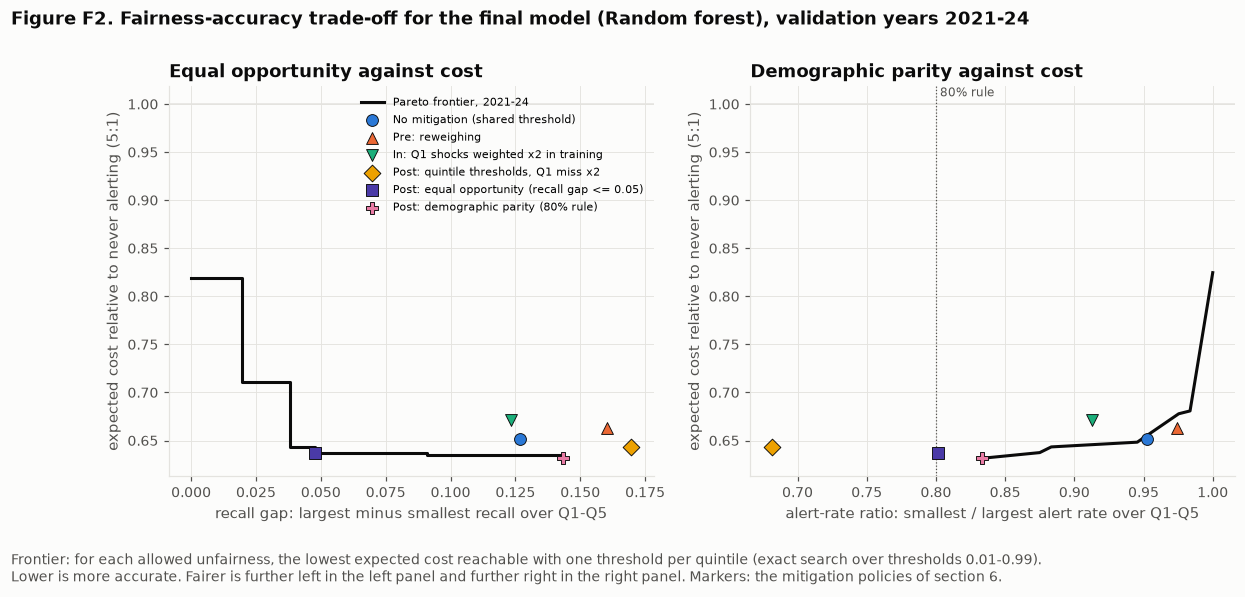

,eps,fairness (val),fairness (test),cost / never (val),accuracy (val),cost / never (test),accuracy (test)
0,0.00,0.000,0.000,0.819,0.201,2.400,0.077
1,0.02,0.020,0.190,0.711,0.394,1.526,0.484
2,0.04,0.038,0.127,0.643,0.576,1.149,0.708
3,0.06,0.048,0.270,0.637,0.574,1.149,0.699
5,0.10,0.091,0.270,0.634,0.569,1.126,0.699
10,0.20,0.143,0.270,0.632,0.564,1.149,0.690
15,0.30,0.143,0.270,0.632,0.564,1.149,0.690
30,0.60,0.143,0.270,0.632,0.564,1.149,0.690


In [12]:
# Figure F2: the fairness-accuracy trade-off (Pareto frontier) for quintile-specific thresholds
never_v = B.COST_FN * yv.sum()
def frontier_eval(fr, kind):
    out = []
    for _, r in fr.iterrows():
        rr = A.group_rates(yv, oof[FINAL][val], gv, r["thresholds"])
        rt = A.group_rates(yt.to_numpy(), p_test[FINAL], g_te, r["thresholds"])
        fair_v = {"TPR": rr["TPR (recall)"].max() - rr["TPR (recall)"].min(),
                  "DI": rr["alert rate"].min() / rr["alert rate"].max()}[kind]
        fair_t = {"TPR": rt["TPR (recall)"].max() - rt["TPR (recall)"].min(),
                  "DI": rt["alert rate"].min() / rt["alert rate"].max()}[kind]
        out.append({"eps": r["eps"], "fairness (val)": fair_v, "fairness (test)": fair_t,
                    "cost / never (val)": r["cost"] / never_v,
                    "accuracy (val)": (rr["TP"].sum() + rr["TN"].sum()) / len(yv),
                    "cost / never (test)": A.total_cost(yt.to_numpy(), p_test[FINAL], g_te, r["thresholds"]) / (B.COST_FN * yt.sum()),
                    "accuracy (test)": (rt["TP"].sum() + rt["TN"].sum()) / len(yt)})
    return pd.DataFrame(out)
fe_tpr, fe_di = frontier_eval(fr_tpr, "TPR"), frontier_eval(fr_di, "DI")
fe_tpr.to_csv(TABLE_DIR / "m4_pareto_equal_opportunity.csv", index=False)
fe_di.to_csv(TABLE_DIR / "m4_pareto_demographic_parity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
marks = {"No mitigation (shared threshold)": ("o", SERIES[0]), "Pre: reweighing": ("^", SERIES[1]),
         "In: Q1 shocks weighted x2 in training": ("v", SERIES[2]), "Post: quintile thresholds, Q1 miss x2": ("D", SERIES[3]),
         f"Post: equal opportunity (recall gap <= {EO_EPS:.2f})": ("s", SERIES[6]), "Post: demographic parity (80% rule)": ("P", SERIES[4])}
for ax, fe, kind, xlab in [(axes[0], fe_tpr, "TPR", "recall gap: largest minus smallest recall over Q1-Q5"),
                           (axes[1], fe_di, "DI", "alert-rate ratio: smallest / largest alert rate over Q1-Q5")]:
    ax.plot(fe["fairness (val)"], fe["cost / never (val)"], color=INK, lw=2, drawstyle="steps-post" if kind == "TPR" else "default",
            label="Pareto frontier, 2021-24")
    for k, v in policies.items():
        rr = A.group_rates(yv, v["oof"][val], gv, v["thr"])
        fx = rr["TPR (recall)"].max() - rr["TPR (recall)"].min() if kind == "TPR" else rr["alert rate"].min() / rr["alert rate"].max()
        mk, col = marks[k]
        ax.scatter(fx, A.total_cost(yv, v["oof"][val], gv, v["thr"]) / never_v, marker=mk, s=60, color=col,
                   edgecolor=INK, linewidth=0.6, zorder=4, label=k)
    ax.axhline(1, color=GRID, lw=1)
    ax.set(xlabel=xlab, ylabel="expected cost relative to never alerting (5:1)")
axes[1].axvline(0.8, color=INK_SECONDARY, lw=0.8, ls=":")
axes[1].text(0.8, axes[1].get_ylim()[1], " 80% rule", color=INK_SECONDARY, va="top", fontsize=8)
axes[0].set_title("Equal opportunity against cost")
axes[1].set_title("Demographic parity against cost")
axes[0].legend(fontsize=7.5, loc="upper right")
fig.suptitle(f"Figure F2. Fairness-accuracy trade-off for the final model ({FINAL}), validation years 2021-24", x=0.01,
             ha="left", fontweight="bold", color=INK, y=1.03)
caption(fig, "Frontier: for each allowed unfairness, the lowest expected cost reachable with one threshold per quintile "
             "(exact search over thresholds 0.01-0.99).\nLower is more accurate. Fairer is further left in the left panel "
             "and further right in the right panel. Markers: the mitigation policies of section 6.", y=-0.04)
fig.savefig(FIG_DIR / "figF2_pareto_frontier.png")
plt.show()
display(fe_tpr.iloc[[0, 1, 2, 3, 5, 10, 15, -1]].round(3))

**Reading the trade-off**
* **Fairness is cheap until it has to be perfect.** Allowing the five recalls to differ by up to 0.04 costs 0.643 of
  never alerting, which is cheaper than the shared threshold (0.651, recall gap 0.13). From a gap of 0.05 the frontier is
  flat at 0.632 to 0.637. Only exact equality is expensive. A gap of 0.02 costs 0.711, and a gap of zero is reachable
  only by alerting almost every week (0.819).
* **The shared threshold lies above the frontier.** Quintile thresholds exist that are both fairer and cheaper. This is
  the main practical result of the audit.
* **Demographic parity is almost free.** Its frontier is nearly flat. An alert-rate ratio of 0.95 costs 0.648 and the
  80% rule costs nothing extra (0.632), because the forest already warns all quintiles at similar rates. Only exact
  parity is expensive (0.825).
* **The frontier is drawn on the validation years.** On the test period the frontier thresholds for tolerances of 0.04
  and more cost 1.13 to 1.15 of never alerting, and their recall gaps scatter between 0.13 and 0.27, so the trade-off has to be re-estimated whenever the
  regime changes.

## 8. Asymmetric thresholds across groups

The cost-based quintile thresholds depend on how much more a missed Q1 shock is assumed to cost. The table shows the Q1
and Q5 thresholds, recalls and false-positive rates for a Q1 miss cost of 1, 1.5, 2 and 3 times a miss elsewhere. The
figure shows the threshold curve of every quintile, the cost of that quintile's errors at every threshold. Each curve
has its minimum at a different place, which is why one shared threshold cannot be optimal for every group.

In [13]:
# Asymmetric costs across groups: how the Q1 threshold and the outcomes move with the Q1 miss cost
rows = []
for mult in A.MISS_MULTS:
    c = A.miss_costs(mult)
    t = A.group_thresholds(y, oof[FINAL], g_tr, c)
    for period, yy, gg, pp in [("2021-24 (out-of-fold)", yv, gv, oof[FINAL][val]), ("test 2025-26", yt.to_numpy(), g_te, p_test[FINAL])]:
        r = A.group_rates(yy, pp, gg, t)
        rows.append({"Q1 miss cost (x a miss elsewhere)": mult, "period": period, "threshold Q1": t["Q1"], "threshold Q5": t["Q5"],
                     "recall Q1": r.loc["Q1", "TPR (recall)"], "recall Q5": r.loc["Q5", "TPR (recall)"],
                     "FPR Q1": r.loc["Q1", "FPR"], "FPR Q5": r.loc["Q5", "FPR"],
                     "cost / never (5:1)": A.total_cost(yy, pp, gg, t) / (B.COST_FN * yy.sum())})
asym = pd.DataFrame(rows).set_index(["period", "Q1 miss cost (x a miss elsewhere)"])
display(asym.round(3))
asym.to_csv(TABLE_DIR / "m4_q1_cost_sensitivity.csv")

,,threshold Q1,threshold Q5,recall Q1,recall Q5,FPR Q1,FPR Q5,cost / never (5:1)
period,Q1 miss cost (x a miss elsewhere),,,,,,,
2021-24 (out-of-fold),1.0,0.14,0.12,0.737,0.868,0.459,0.506,0.632
test 2025-26,1.0,0.14,0.12,0.571,0.667,0.298,0.329,1.149
2021-24 (out-of-fold),1.5,0.09,0.12,0.895,0.868,0.706,0.506,0.643
test 2025-26,1.5,0.09,0.12,0.714,0.667,0.524,0.329,1.229
2021-24 (out-of-fold),2.0,0.09,0.12,0.895,0.868,0.706,0.506,0.643
test 2025-26,2.0,0.09,0.12,0.714,0.667,0.524,0.329,1.229
2021-24 (out-of-fold),3.0,0.01,0.12,1.000,0.868,1.000,0.506,0.673
test 2025-26,3.0,0.01,0.12,1.000,0.667,1.000,0.329,1.400


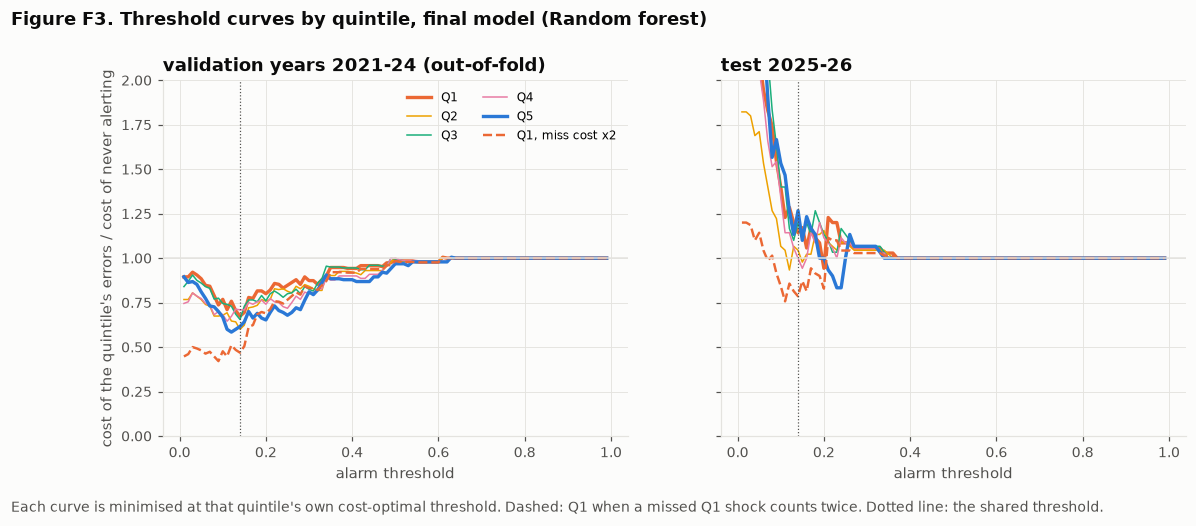

In [14]:
# Figure F3: threshold curves for each quintile (expected cost of that quintile's errors at every threshold)
grid_t = np.round(np.arange(0.01, 1.0, 0.01), 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (period, yy, gg, pp) in zip(axes, [("validation years 2021-24 (out-of-fold)", yv, gv, oof[FINAL][val]),
                                           ("test 2025-26", yt.to_numpy(), g_te, p_test[FINAL])]):
    for g in GROUPS:
        m = gg == g
        never = B.COST_FN * yy[m].sum()
        cc = [B.expected_cost(yy[m], pp[m], t) / never for t in grid_t]
        ax.plot(grid_t, cc, color=GROUP_COLORS[g], lw=2.2 if g in ("Q1", "Q5") else 1.0, label=g)
    m = gg == "Q1"
    cc2 = [B.expected_cost(yy[m], pp[m], t, 1, B.COST_FN * A.Q1_MISS_MULT) / (B.COST_FN * A.Q1_MISS_MULT * yy[m].sum()) for t in grid_t]
    ax.plot(grid_t, cc2, color=GROUP_COLORS["Q1"], lw=1.6, ls="--", label="Q1, miss cost x2")
    ax.axhline(1, color=GRID, lw=1)
    ax.axvline(thr[FINAL], color=INK_SECONDARY, lw=0.8, ls=":")
    ax.set(xlabel="alarm threshold", title=period, ylim=(0, 2))
axes[0].set_ylabel("cost of the quintile's errors / cost of never alerting")
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle(f"Figure F3. Threshold curves by quintile, final model ({FINAL})", x=0.01, ha="left", fontweight="bold",
             color=INK, y=1.03)
caption(fig, "Each curve is minimised at that quintile's own cost-optimal threshold. Dashed: Q1 when a missed Q1 shock counts "
             "twice. Dotted line: the shared threshold.", y=-0.03)
fig.savefig(FIG_DIR / "figF3_threshold_curves_by_quintile.png")
plt.show()

**Reading the asymmetric thresholds**
* With equal miss costs for every quintile, the cost-optimal thresholds already differ (Q1 0.14, Q5 0.12). The best
  shared threshold is a compromise between them.
* Counting a missed Q1 shock 1.5 or 2 times as much lowers Q1's threshold to 0.09. Q1's recall rises from 0.74 to 0.89,
  at the price of a false-positive rate of 0.71 for Q1, and the total cost at the uniform 5 : 1 rate rises only from
  0.632 to 0.643.
* At 3 times, Q1's best threshold drops to 0.01, which means alerting for Q1 every week. A weight that high turns the
  early warning into a standing top-up for the poorest quintile.
* Figure F3 shows why the thresholds differ. Each quintile's cost curve has its minimum in a different place, and Q1's
  curve becomes flat and low at small thresholds once its misses count twice.

## 9. Recommended operating policy

1. **Model:** the random forest of notebook 05, retrained on all available weeks.
2. **Thresholds:** one per quintile, set as the cheapest thresholds whose recalls differ by at most 0.05 (equal
   opportunity). In the validation years this was fairer than one shared threshold (recall gap 0.05 against 0.13) and
   cheaper (0.637 against 0.651 of the cost of never alerting).
3. **If the agency decides to give the poorest priority,** the cost-based thresholds with a missed Q1 shock counted twice
   are the equity option. They raise Q1's recall to about 0.89 at the price of more Q1 false alarms. This is a policy
   choice for the agency and the people affected, not a modelling result.
4. **Re-choose the thresholds on recent weeks** whenever the alert rate and the realised shock rate drift apart. In
   2025–26 no fixed threshold beat silence, so this step matters more than the choice between the policies above.
   Milestone 5 will test how quickly re-chosen thresholds recover.
5. **Monitor recall, false-positive rate and alert rate by quintile every month**, with the definitions of §2.

## 10. FATEN principles: how does the final system measure up?

| Principle | What it asks here | Evidence from this audit | Remaining risk | Safeguard |
|---|---|---|---|---|
| **Fairness** | errors shared equally across quintiles | demographic parity holds (ratio 1.05), Q1's recall is 2.6 points below Q5's, and quintile thresholds cut the largest recall gap to 0.05 | the forest ranks Q1's weeks worse (AUC 0.64 against 0.72), and gaps cannot be measured in a calm year | quintile thresholds, monthly fairness dashboard |
| **Autonomy** | people and officials keep control over decisions | the model informs a decision by staff and never sets anyone's eligibility. It uses no personal data | staff may defer to the model (automation bias) | show the probability and its reasons, keep the decision and any override with staff |
| **Trust** | the system is transparent and reliable | open features, thresholds and error analysis. Calibrated in the validation years (Brier 0.152 against 0.158) | in 2025–26 alarms were right less than one time in six, and repeated false alarms erode trust | publish the alarm record, re-choose thresholds by regime (Milestone 5) |
| **Equity** | support follows need, not only equal numbers | a Q1 miss can be weighted twice, which raises Q1's recall to 0.89 | the households in greatest need (rural, outside the 2015-16 weights) are not in the data | the weight is set by the agency with those affected, and rural price data are added |
| **Non-maleficence** | the system does no harm | false alarms are transfers, not losses, and misses are the costly error | a public warning could feed hoarding, and "no alarm" could be misread as "no need" | alarms stay internal, and the alarm adds to targeting, never replaces it |

## 11. Living lab: how the system would behave in a real pilot

A living lab tests a system with its real users, in its real setting, while it is watched closely and can be changed.
For this model that means a pilot of about six months in which the weekly forecast goes to a social-protection desk
(BISP or a provincial social-protection authority) and staff decide what to do with it.

**The weekly cycle.** PBS releases the SPI → the model is re-run with the new week → quintile alarms and probabilities
go to the desk with the reason behind each alarm (which signals were on) → staff decide whether to prepare or bring
forward a top-up → the next release shows whether the shock came, and the result is logged.

**Stakeholders.** BISP and provincial social-protection staff (users), the Ministry of Finance (budget), PBS (data),
NEPRA, OGRA and the ECC (who set administered prices), beneficiary households and the civil-society groups that speak
for them, and an independent reviewer.

| Failure mode | What we saw in our data | Safeguard |
|---|---|---|
| The regime changes and the threshold no longer fits | a threshold chosen on 2021–24 over-alerted in calm 2025–26 (§8 of notebook 05) | track the alert rate against the realised shock rate every month, re-choose the threshold on recent weeks, retrain when they drift apart (Milestone 5) |
| The first wave of an administered price rise is missed | utility tariff and first petrol increases had no lead signal in Milestone 3 | an agreement that NEPRA, OGRA and the ECC notify the desk before a decision takes effect |
| One quintile is served worse | Q1's recall trails Q5's (§2, §3) | quintile thresholds (§6) and a fairness dashboard with recall and alert rate by quintile, reviewed monthly |
| Households outside the data | 17 cities only, no rural prices, 2015-16 weights | never use the alarm as the only trigger, add rural price data, re-weight the quintiles when PBS updates them |
| Data arrive late or are revised | revised SPI values were used in training | run the pilot on first releases and keep a record of every data version |
| Staff stop questioning the model, or stop listening to it | many false alarms per real shock | show the probability and its reasons, keep the decision with staff, report the alarm record openly |
| A public warning feeds expectations or hoarding | not testable in our data | keep alarms internal, publish results only with a delay |
| Pressure to silence alarms before a budget or election | not testable in our data | log every alarm and every decision so that overrides can be reviewed |

**Digital marginalization.** The households least visible to the data, rural families and those whose consumption the
2015-16 weights no longer describe, are the ones most likely to be left out by any system that only acts on what the
SPI measures. The model should therefore add to existing targeting, never replace it, and an alarm that does not
fire must never be read as "no help needed".

## 12. Summary of the fairness audit

1. **Sensitive attribute:** consumption quintile (Q1 unprivileged, Q5 privileged). The favourable outcome is an alarm.
2. **Demographic parity holds** for every learner (disparate impact 0.96 to 1.05, 80% rule met), because most signals are
   shared by all quintiles.
3. **Equal opportunity leans slightly against Q1** in every learner (forest: −2.6 points, not significant). The larger
   difference is in ranking: the forest's AUC is 0.64 for Q1 and 0.72 for Q5.
4. **H5 is not supported at the 5% level** (Brier 0.148 against 0.136, p = 0.26), although the direction is as expected.
5. **Mechanism:** Q1's shocks are more often perishable-driven (42% against 24% for Q5), and perishable and tariff shocks
   are the ones the model catches least (recall 0.62 and 0.69, against 0.88 for fuel).
6. **Mitigation:** reweighing does nothing useful here, because base rates are already equal. Group-weighted training moves
   the imbalance. **Quintile thresholds** are fairer and cheaper than one shared threshold in the validation years.
7. **Trade-off:** fairness is cheap until it must be exact. The shared threshold lies above the Pareto frontier.
8. **Test period:** with 6 to 9 shocks per quintile, fairness cannot be measured precisely, and no policy beats never
   alerting at 5 : 1. Re-choosing the thresholds by regime is the next step (Milestone 5).